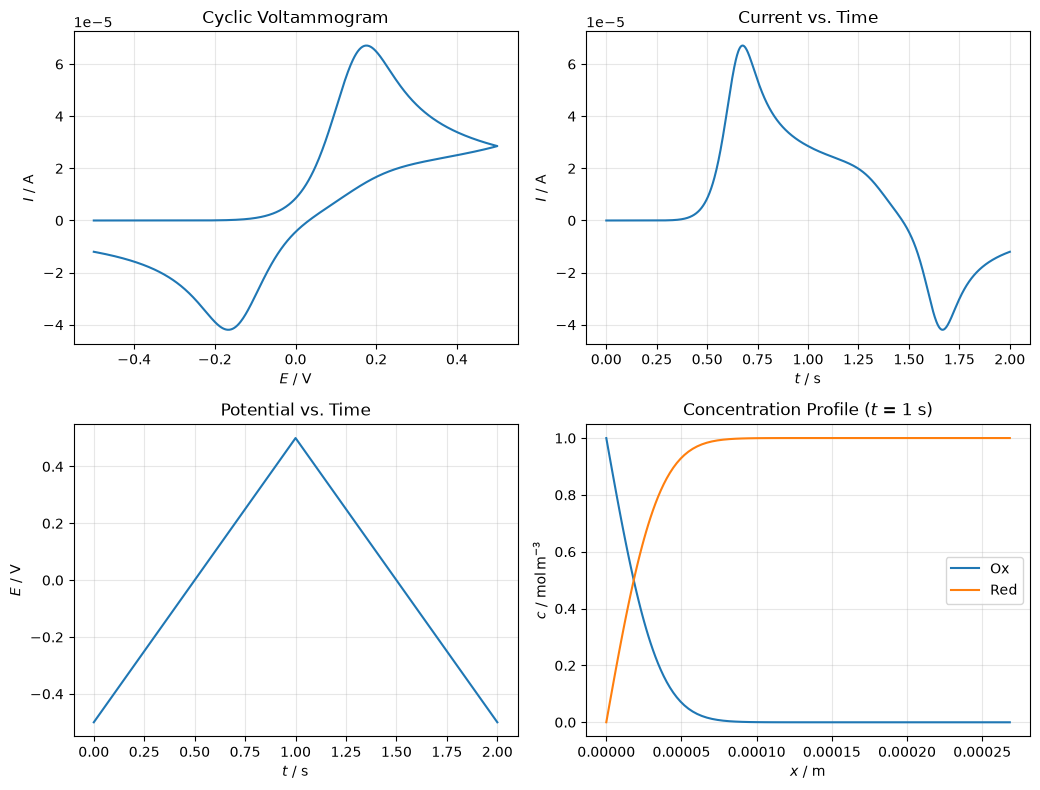

In [6]:
import matplotlib.pyplot as plt

from softpotato.reactions import Species, ButlerVolmer
from softpotato.geometry import PlanarGeometry
from softpotato.techniques import CyclicVoltammetry, simulate

# Constants
D = 1e-9 # m^2/s
cR_bulk = 1 # mol/m^3 (1 mM)
cO_bulk = 0 # mol/m^3
area = 1e-5 # m^2 (1 cm^2)
E0 = 0 # V
n_rxn = 1
k0 = 1e-5 # m/s
alpha = 0.5

# Define CV
cv = CyclicVoltammetry(
    E_start = -0.5,
    E_vertex1 = 0.5,
    E_vertex2 = -0.5,
    scan_rate = 1
)

# Species definition
red = Species(
    name = "Red", 
    diffusivity = D, 
    bulk_concentration = cR_bulk, 
    standard_potential = E0, 
    n_electrons = -n_rxn
)

ox = Species(
    name = "Ox",
    diffusivity = D,
    bulk_concentration = cO_bulk,
    standard_potential = E0,
    n_electrons = n_rxn
)

# Set planar geometry
geometry = PlanarGeometry(area)

# Run simulation
# The mechanism is written in the order of the reaction: Ox + e- <-> Red
sim = simulate(
    technique = cv,
    mechanism = [ox, red],
    geometry = geometry,
    kinetics = ButlerVolmer(k0=k0, alpha=alpha)
)

# Generate default plots
fig_summary, axes = sim.plot_summary(t=1)
plt.show()

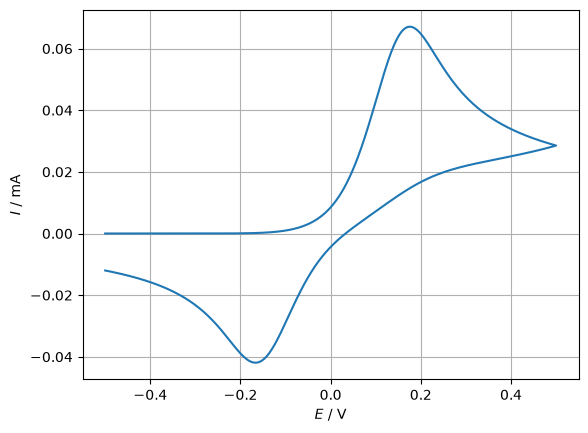

In [7]:
plt.figure()
plt.plot(sim.potential, sim.current*1e3)
plt.xlabel("$E$ / V")
plt.ylabel("$I$ / mA")
plt.grid()
plt.show()

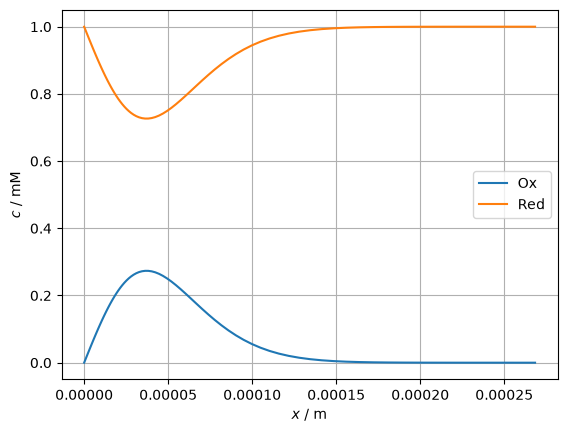

In [8]:
plt.figure()
plt.plot(sim.x, sim.concentrations["Ox"][-1,:], label="Ox")
plt.plot(sim.x, sim.concentrations["Red"][-1,:], label="Red")
plt.xlabel("$x$ / m")
plt.ylabel("$c$ / mM")
plt.grid()
plt.legend()
plt.show()

In [9]:
cv.scan_rate

1.0

In [10]:
from softpotato.analytical.voltammetry import randles_sevcik_quasi
from softpotato.analytical.benchmark import compute_error_metrics

i_sim = sim.current.max()
i_rs = -randles_sevcik_quasi(
    v = cv.scan_rate, 
    c_bulk = cR_bulk, 
    D = D, 
    area = area, 
    n = n_rxn, 
    k0 = k0, 
    alpha = alpha
)

print(f"Simulated peak current: {i_sim:.2e} A")
print(f"Analytical peak current: {i_rs:.2e} A")

error = compute_error_metrics(i_sim, i_rs)
for k, v in error.to_dict().items():
    print(f"{k}: {v:.2e}")

Simulated peak current: 6.71e-05 A
Analytical peak current: 6.75e-05 A
rmse: 3.57e-07
max_abs_error: 3.57e-07
l2_error: 5.29e-03
mean_abs_error: 3.57e-07
mean_rel_error: 5.29e-03
max_rel_error: 5.29e-03
